In [2]:
import os
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from keras.layers import Input
from keras.models import Model, Sequential
from keras.layers import Reshape, Dense, Dropout, Flatten, Input, LeakyReLU,ReLU, BatchNormalization, Conv2DTranspose,Conv2D
from keras.datasets import mnist
from keras.optimizers import Adam

In [3]:
gpus = tf.config.experimental.list_physical_devices('GPU')

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled for GPU")
    except RuntimeError as e:
        print(f"Error setting memory growth: {e}")

Memory growth enabled for GPU


In [4]:
# MNIST data
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# X_train = X_train.astype(np.float32) / 255
X_train = (X_train.astype(np.float32) - 127.5) / 127.5

In [5]:
BATCH_SIZE = 128

In [6]:
dataset = tf.data.Dataset.from_tensor_slices(X_train).shuffle(60000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1783194473.603227    8088 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 7119 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


In [7]:
randomDim = 100

In [8]:
# DCGAN

In [9]:
generator = Sequential()

generator.add(Input(shape=(randomDim,)))
generator.add(Dense(7 * 7 * 256))
generator.add(Reshape((7, 7, 256)))
generator.add(BatchNormalization())
generator.add(LeakyReLU(0.2))

generator.add(Conv2DTranspose(128, kernel_size=3, strides=2, padding='same'))
generator.add(BatchNormalization())
generator.add(LeakyReLU(0.2))

generator.add(Conv2DTranspose(64, kernel_size=3, strides=2, padding='same'))
generator.add(BatchNormalization())
generator.add(LeakyReLU(0.2))

generator.add(Conv2D(1, kernel_size=3, padding='same', activation='tanh'))
generator.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,266,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 1)      │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,638,145 (6.25 MB)

 Trainable params: 1,637,249 (6.25 MB)

 Non-trainable params: 896 (3.50 KB)

In [10]:
# Discriminator Network
discriminator = Sequential()
discriminator.add(Input(shape=(28, 28, 1)))

discriminator.add(Conv2D(32, kernel_size=3, strides=2, padding='same'))
discriminator.add(BatchNormalization())
discriminator.add(LeakyReLU(0.2))

discriminator.add(Conv2D(64, kernel_size=3, strides=2, padding='same'))
discriminator.add(BatchNormalization())
discriminator.add(LeakyReLU(0.2))

discriminator.add(Conv2D(128, kernel_size=3, strides=2, padding='same'))
discriminator.add(BatchNormalization())
discriminator.add(LeakyReLU(0.2))

discriminator.add(Flatten())
discriminator.add(Dropout(0.2))
discriminator.add(Dense(1, activation='sigmoid'))

discriminator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,617 (373.50 KB)

 Trainable params: 95,169 (371.75 KB)

 Non-trainable params: 448 (1.75 KB)

In [11]:
# Train

In [16]:
def plotGeneratedImages(epoch, examples=100, dim=(10, 10), figsize=(10, 10)):
    noise = np.random.normal(0, 1, size=[examples, randomDim])
    generatedImages = generator.predict(noise)
    generatedImages = generatedImages.reshape(examples, 28, 28)

    plt.figure(figsize=figsize)
    for i in range(generatedImages.shape[0]):
        plt.subplot(dim[0], dim[1], i+1)
        plt.imshow(generatedImages[i], interpolation='nearest', cmap='gray')
        plt.axis('off')
    plt.tight_layout()
    out_dir = './generated image/DCGAN2/'
    os.makedirs(out_dir,exist_ok=True)
    out = os.path.join(out_dir, 'DCGAN_generated_image_epoch_%d.png' % epoch)
    plt.savefig(out)
    plt.close()

In [17]:
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.00015)

cross_entropy = tf.keras.losses.BinaryCrossentropy()

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output) * 0.9, real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

In [18]:
@tf.function
def train_step(images):
    batch_size = tf.shape(images)[0]
    noise_d = tf.random.normal([batch_size, randomDim])
    
    with tf.GradientTape() as disc_tape:
        generated_images = generator(noise_d, training=True)
        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)
        disc_loss = discriminator_loss(real_output, fake_output)
    
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    
    noise_g = tf.random.normal([batch_size, randomDim])
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise_g, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)
        
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    
    return disc_loss, gen_loss

In [19]:
epochs = 120

dLosses = []
gLosses = []

for e in range(1, epochs + 1):
    epoch_d_loss = []
    epoch_g_loss = []

    print('-' * 10, 'Epoch %d' % e, '-' * 10)
    for image_batch in tqdm(dataset):
        d_loss, g_loss = train_step(image_batch)

        epoch_d_loss.append(d_loss)
        epoch_g_loss.append(g_loss)
    
    avg_d_loss = np.mean(epoch_d_loss)
    avg_g_loss = np.mean(epoch_g_loss)
    
    dLosses.append(avg_d_loss)
    gLosses.append(avg_g_loss)

    print(f"Epoch {e}, Discriminator Loss: {avg_d_loss}, Generator Loss: {avg_g_loss}")

    if e == 1 or e % 10 == 0:
        plotGeneratedImages(e)

---------- Epoch 1 ----------


100%|████████████████████████████████████████████████████████████████████████| 469/469 [00:27<00:00, 16.97it/s]

Epoch 1, Discriminator Loss: 1.1261619329452515, Generator Loss: 1.5783368349075317
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


---------- Epoch 2 ----------


100%|████████████████████████████████████████████████████████████████████████| 469/469 [00:21<00:00, 21.34it/s]


...

Epoch 118, Discriminator Loss: 1.1630058288574219, Generator Loss: 1.213669776916504
---------- Epoch 119 ----------


100%|████████████████████████████████████████████████████████████████████████| 469/469 [00:23<00:00, 19.76it/s]


Epoch 119, Discriminator Loss: 1.1690000295639038, Generator Loss: 1.2299100160598755
---------- Epoch 120 ----------


100%|████████████████████████████████████████████████████████████████████████| 469/469 [00:23<00:00, 20.20it/s]

Epoch 120, Discriminator Loss: 1.1727315187454224, Generator Loss: 1.2305210828781128
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


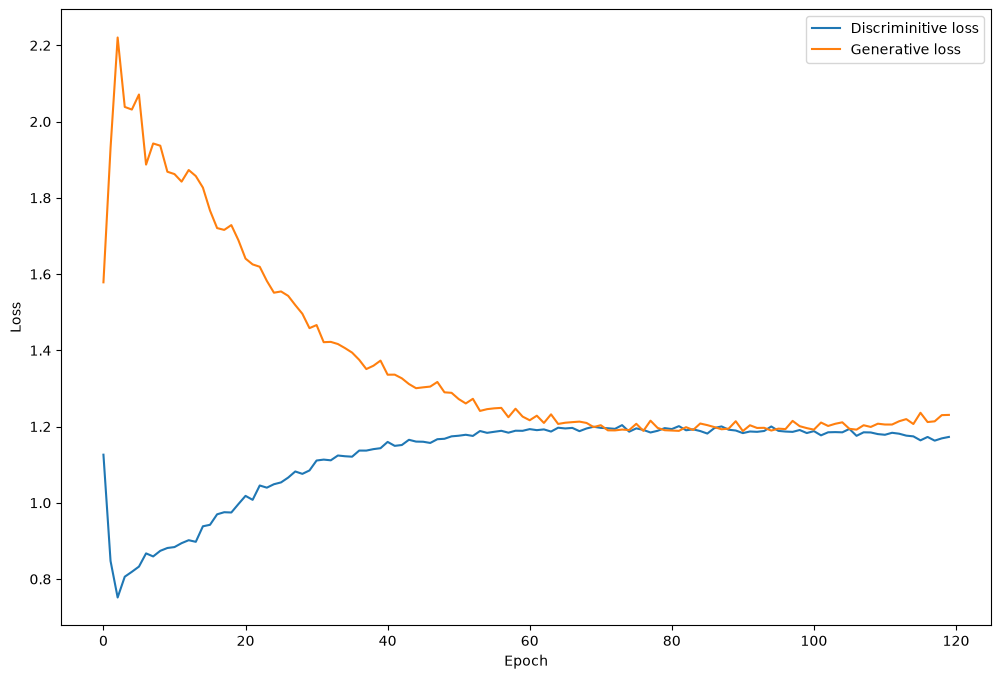

In [20]:
plt.figure(figsize=(12, 8))
plt.plot(dLosses, label='Discriminitive loss')
plt.plot(gLosses, label='Generative loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


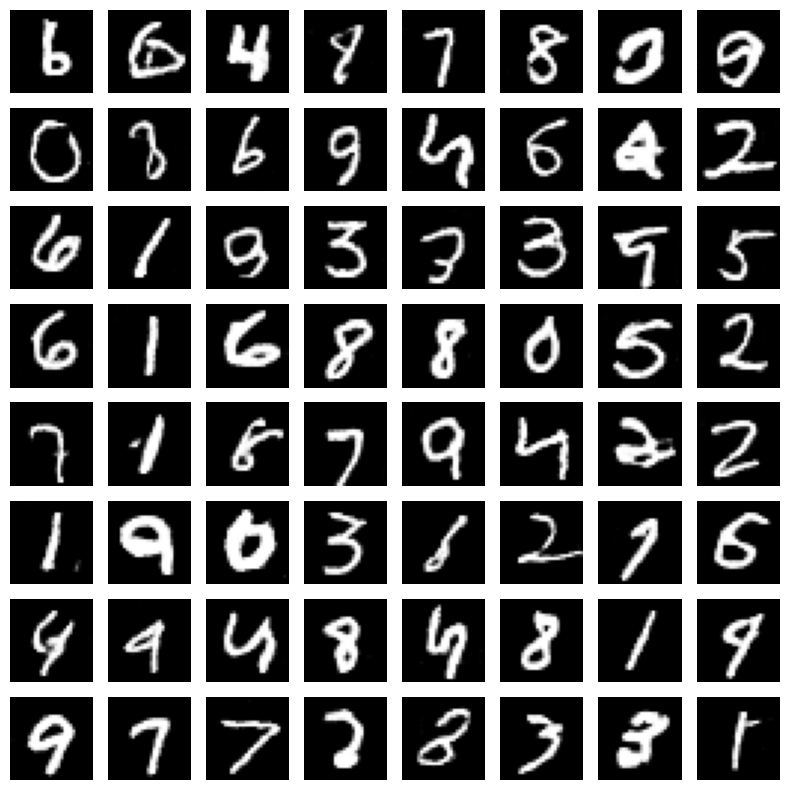

In [21]:
num_images = 64

noise = tf.random.normal(shape=[num_images, 100])

generated_images = generator.predict(noise)

generated_images = generated_images.reshape(num_images, 28, 28)

plt.figure(figsize=(8, 8))
for i in range(num_images):
    plt.subplot(8, 8, i+1)
    plt.imshow(generated_images[i], cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()